# 03 · Candidate Generation and Features

**Round 1 walkthrough:** turn each noisy GPS point into a small set of possible road segments, measure the candidate miss rate, and inspect the feature vector used by all five classifiers.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/"src").exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
DATA=ROOT/"data"/"Student folder"
print("Project:",ROOT,"| data folder available:",DATA.exists())

Project: /Users/yashas/Documents/Codex/2026-11-18/referenced-chatgpt-conversation-this-is-an-2/ML_hackathon | data folder available: True


In [2]:
import pandas as pd, numpy as np
from pathsnap.data import read_trip
from pathsnap.matcher import generate_candidates,FEATURE_NAMES
trip=read_trip(DATA/"train"/"00000001","train")
batch=generate_candidates(trip,k=12)
print("GPS observations:",len(trip.track),"candidate count per observation:",batch.ids.shape[1])
print("Candidate miss rate:",round(float(batch.candidate_miss.mean())*100,2),"%")
obs=10
view=pd.DataFrame(batch.features[obs],columns=FEATURE_NAMES)
view.insert(0,"candidate_arc_id",batch.ids[obs])
view["reference_candidate"]=batch.ids[obs]==batch.truth[obs]
print("Reference-route arc for sample observation:",int(batch.truth[obs]))
display(view.sort_values("distance_m").reset_index(drop=True))

GPS observations: 1315 candidate count per observation: 12
Candidate miss rate: 18.25 %
Reference-route arc for sample observation: 8970


,candidate_arc_id,distance_m,heading_difference_rad,along_segment_fraction,segment_length_m,gps_speed_mps,reference_candidate
0,8970,3.327852,0.064054,0.023994,167.862518,37.617348,True
1,133950,5.224627,0.064908,1.000000,27.416754,37.617348,False
2,139208,31.622494,0.065726,1.000000,63.631401,37.617348,False
3,133949,95.138580,0.066111,1.000000,57.610889,37.617348,False
4,68262,149.057190,0.380472,1.000000,2.499920,37.617348,False
5,68265,149.057190,2.761121,0.000000,2.499920,37.617348,False
6,68264,149.057190,0.188497,0.000000,26.081347,37.617348,False
7,68267,149.057190,2.953096,1.000000,26.081347,37.617348,False
8,68263,149.238831,2.026734,0.000000,5.099653,37.617348,False
9,68260,149.238831,1.114859,1.000000,5.099653,37.617348,False


## Why these five features?

- **Distance to segment (metres):** the nearest physical distance is a direct cue for the road that produced a noisy GPS point.
- **Heading difference (radians):** helps separate parallel or opposite-direction road candidates using recent movement.
- **Along-segment fraction:** shows where the point projects between the candidate segment’s endpoints.
- **Segment length (metres):** provides local geometry context.
- **GPS speed (metres/second):** adds movement context and respects timestamp gaps.

This is a compact, task-motivated first set. A formal feature-ablation experiment remains future work.

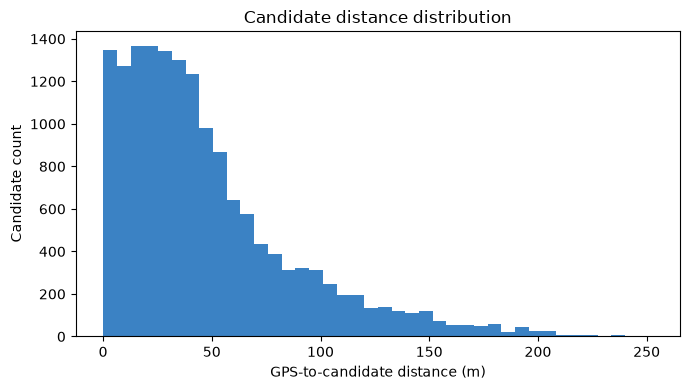

In [3]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(7,4))
ax.hist(batch.features[:,:,0].ravel(),bins=40,color="#3b82c4")
ax.set(xlabel="GPS-to-candidate distance (m)",ylabel="Candidate count",title="Candidate distance distribution")
fig.tight_layout()